# 单翼 10–15 Hz：保留两侧扑翼传动

按实测配置移除右侧翼膜/翼板，只保留左翼；左右扑翼传动机构及减速、滑块机构全部保留。
具体建模为移除 CAD 的 `right_wing` 刚体（含其质量、惯量、被动羽化关节和气动力），
保留 `right_flapping` 刚体、关节和滑块耦合。原双翼模型文件没有修改。
左翼的质量、几何、被动 ±50° 羽化限位及气动参数保持原值。

每隔 1 Hz 独立运行，并校准实际频率误差至 0.01 Hz 内。
每组 2 s、步长 5 µs、采样 2 kHz；排除前 0.6 s 后按完整周期时间积分平均。
图中 Fz 是**单片左翼的气动升力**，正向为世界 +Z；不是支架总反力。
误差棒为各周期均值的最小/最大值，不是置信区间。
尚未读入实测数据，也未据此拟合气动系数。

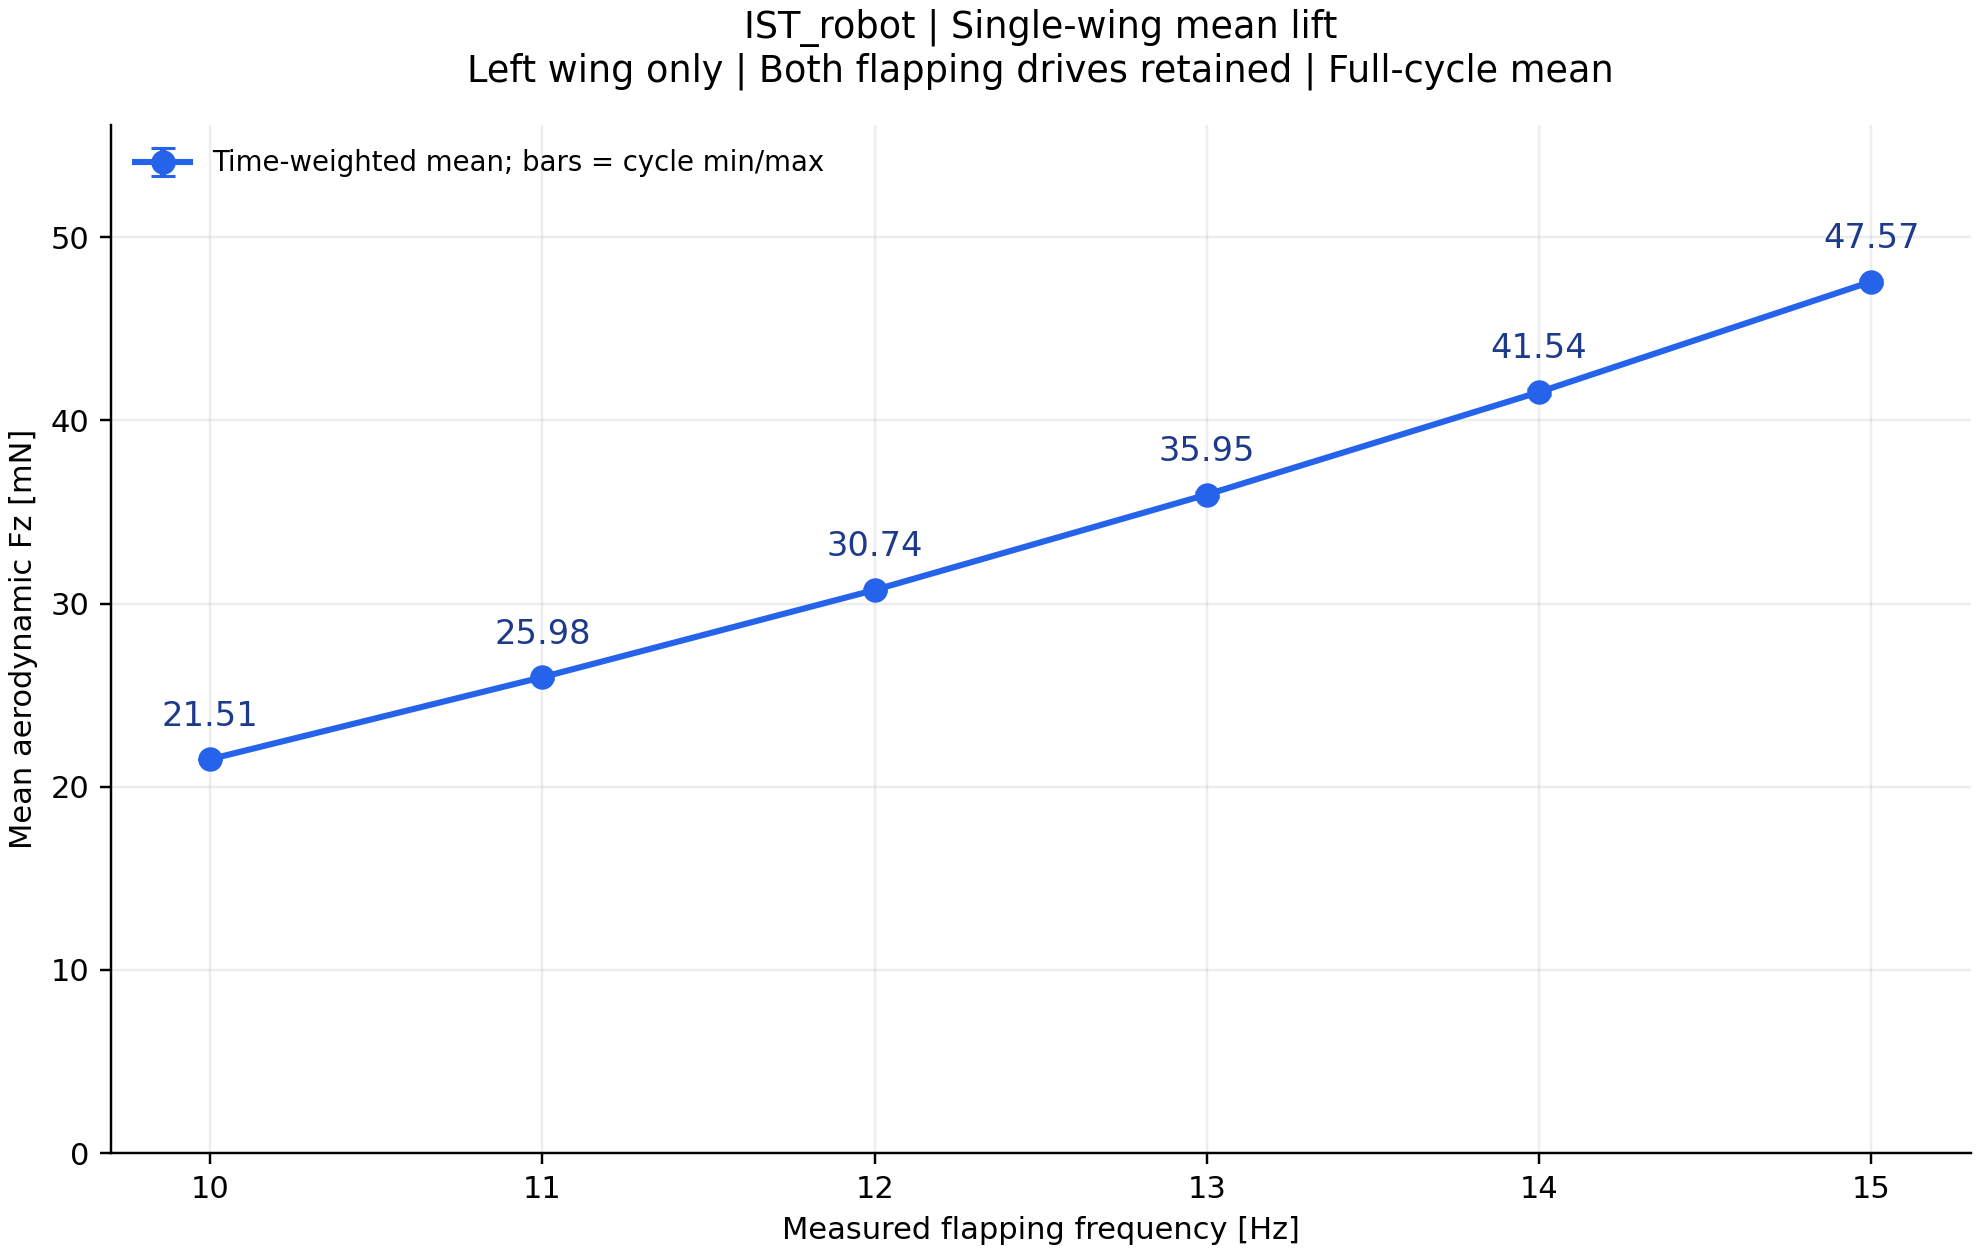

| 目标 Hz | 实际 Hz | 单翼平均 Fz / mN | 周期数 |
|---:|---:|---:|---:|
| 10 | 9.9999 | 21.506 | 13 |
| 11 | 11.0000 | 25.984 | 15 |
| 12 | 12.0000 | 30.741 | 16 |
| 13 | 13.0000 | 35.947 | 18 |
| 14 | 14.0000 | 41.540 | 18 |
| 15 | 15.0000 | 47.570 | 20 |

In [1]:
from pathlib import Path
import sys, json
import numpy as np
from IPython.display import display, Image, Markdown
here = Path.cwd().resolve()
ROOT = next(p for p in (here, *here.parents) if (p / 'flapsim' / 'simulator.py').is_file())
FOLDER = ROOT / 'experiments' / 'fixbase'
sys.path.insert(0, str(FOLDER))
from single_wing_sweep import OUTPUT, single_config, plot
from sweep_frequency import saved_run
from run_15hz import cycle_statistics
config = single_config(OUTPUT / 'model' / 'IST_robot_single_left_wing.xml')
results = json.loads((OUTPUT / 'sweep.json').read_text())
assert len(results) == 6
for r in results:
    data, summary = saved_run(FOLDER / r['source_folder'], config)
    assert summary['wing_bodies'] == ['left_wing']
    assert 'right_flapping_joint_angle_rad' in data
    assert 'right_feathering_joint_angle_rad' not in data
    np.testing.assert_allclose(data['aero_Fz_N'], data['left_aero_Fz_N'], atol=1e-12)
    measured = cycle_statistics(data, target_hz=r['target_wing_frequency_hz'])
    assert abs(measured['measured_wing_frequency_hz']-r['target_wing_frequency_hz']) <= .01
    assert np.isclose(measured['mean_lift_N'], r['mean_lift_N'])
plot(results)
display(Image(filename=str(OUTPUT / 'mean_Fz_vs_frequency.png')))
rows = ['| 目标 Hz | 实际 Hz | 单翼平均 Fz / mN | 周期数 |', '|---:|---:|---:|---:|']
rows += [f"| {r['target_wing_frequency_hz']} | {r['measured_wing_frequency_hz']:.4f} | {r['mean_lift_mN']:.3f} | {r['complete_cycles']} |" for r in results]
display(Markdown(chr(10).join(rows)))

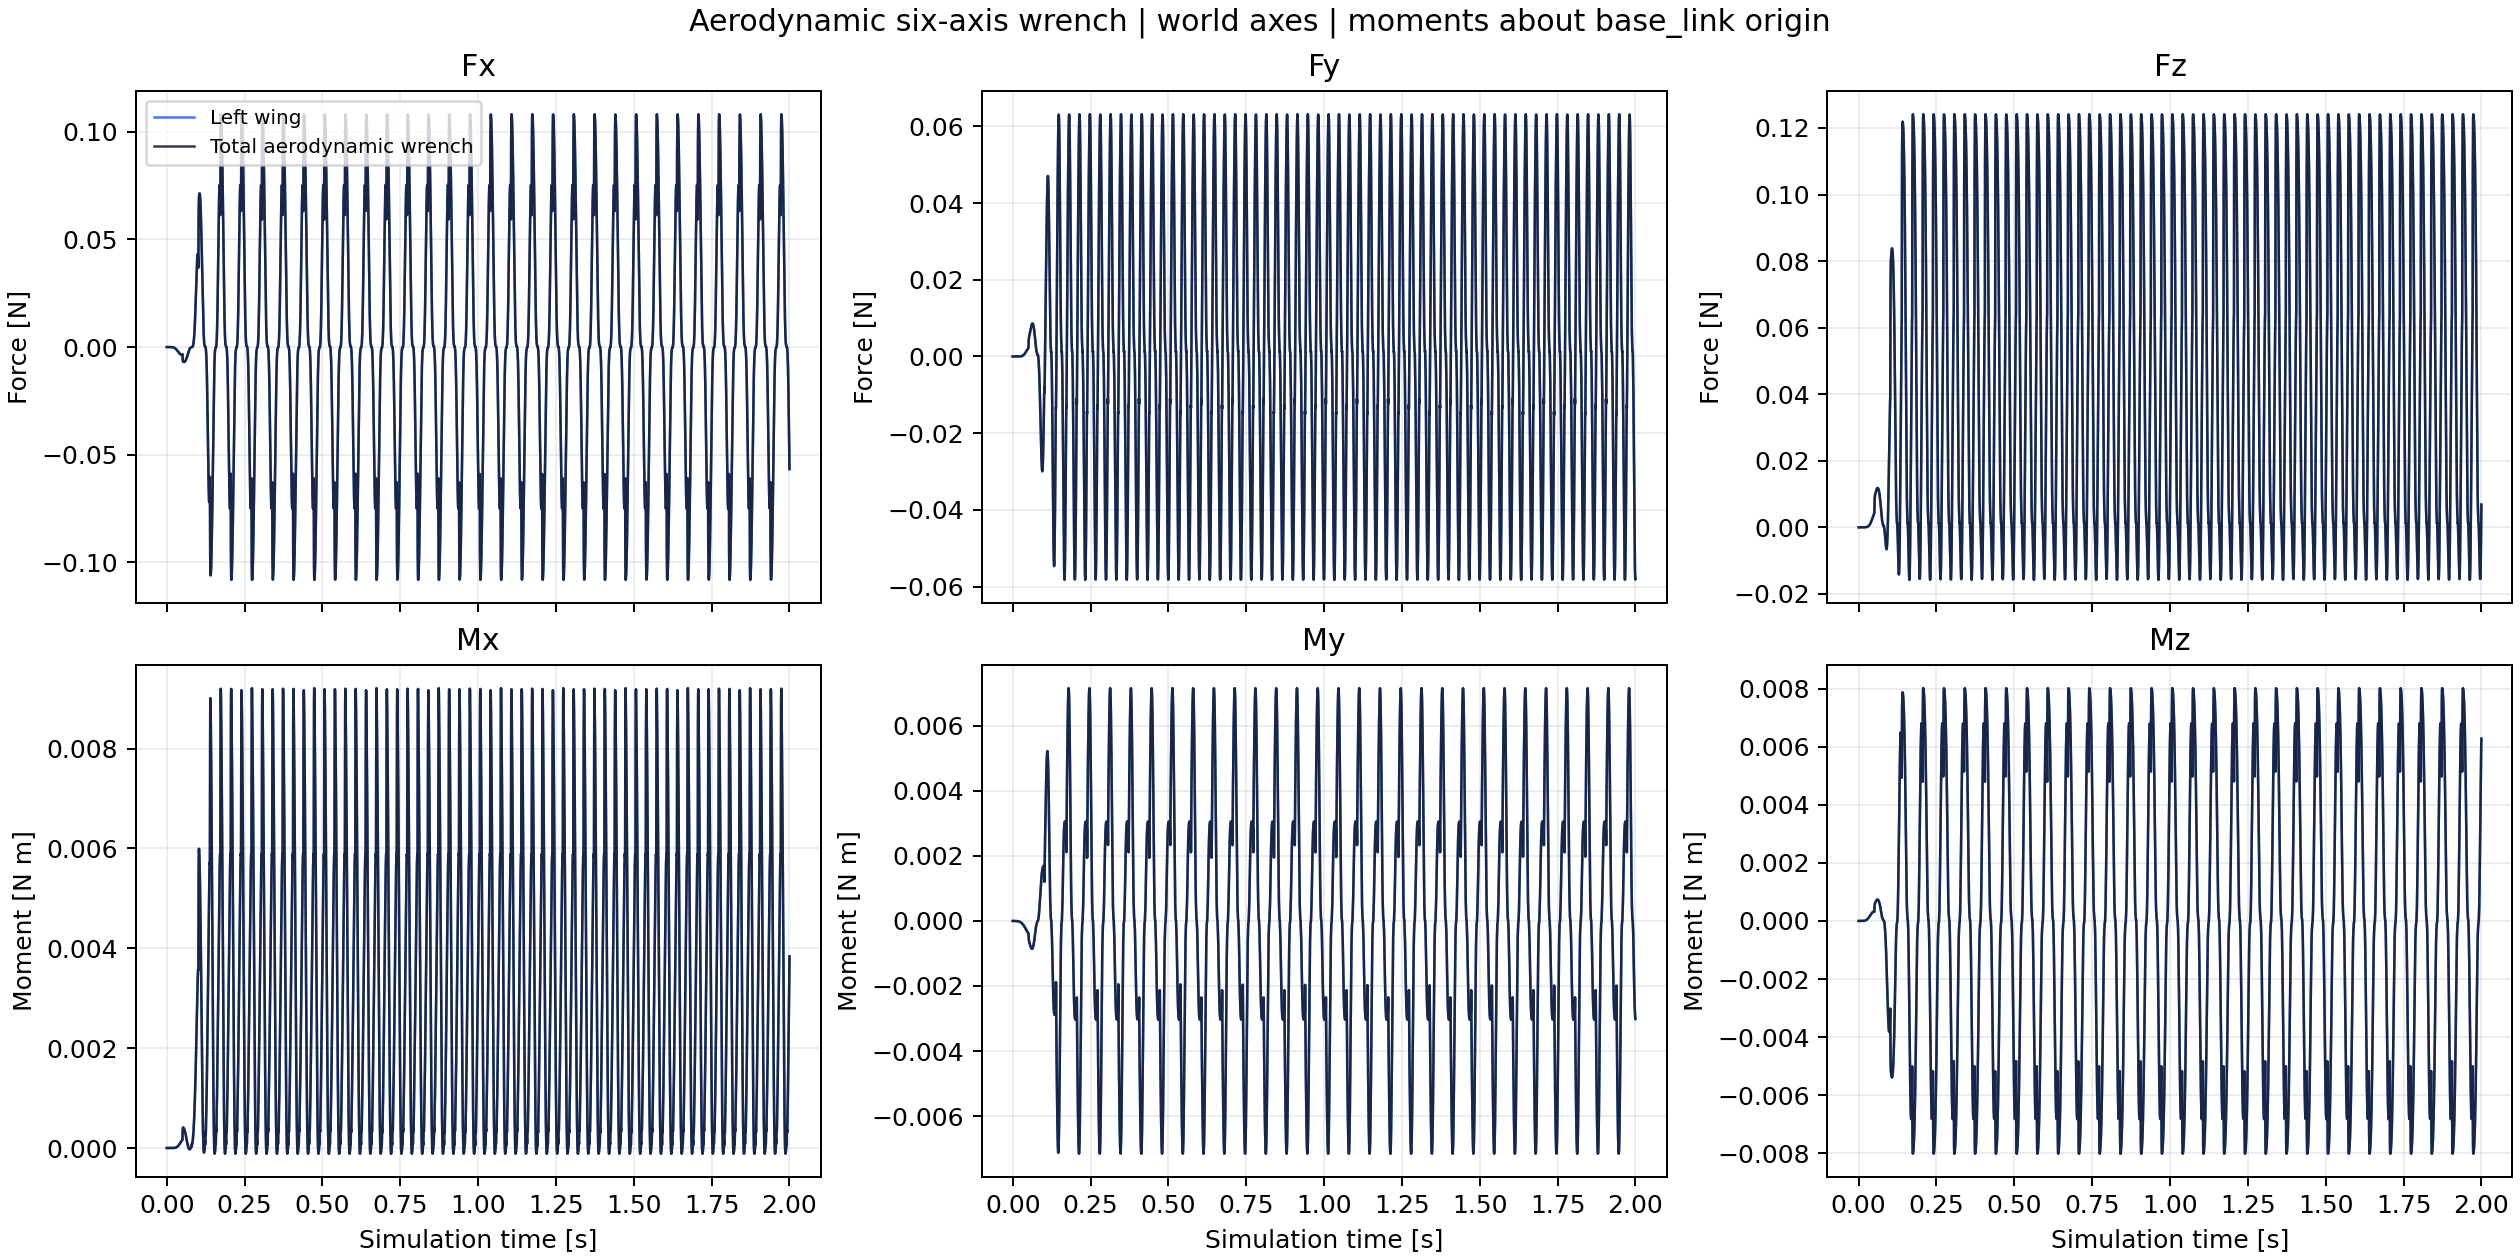

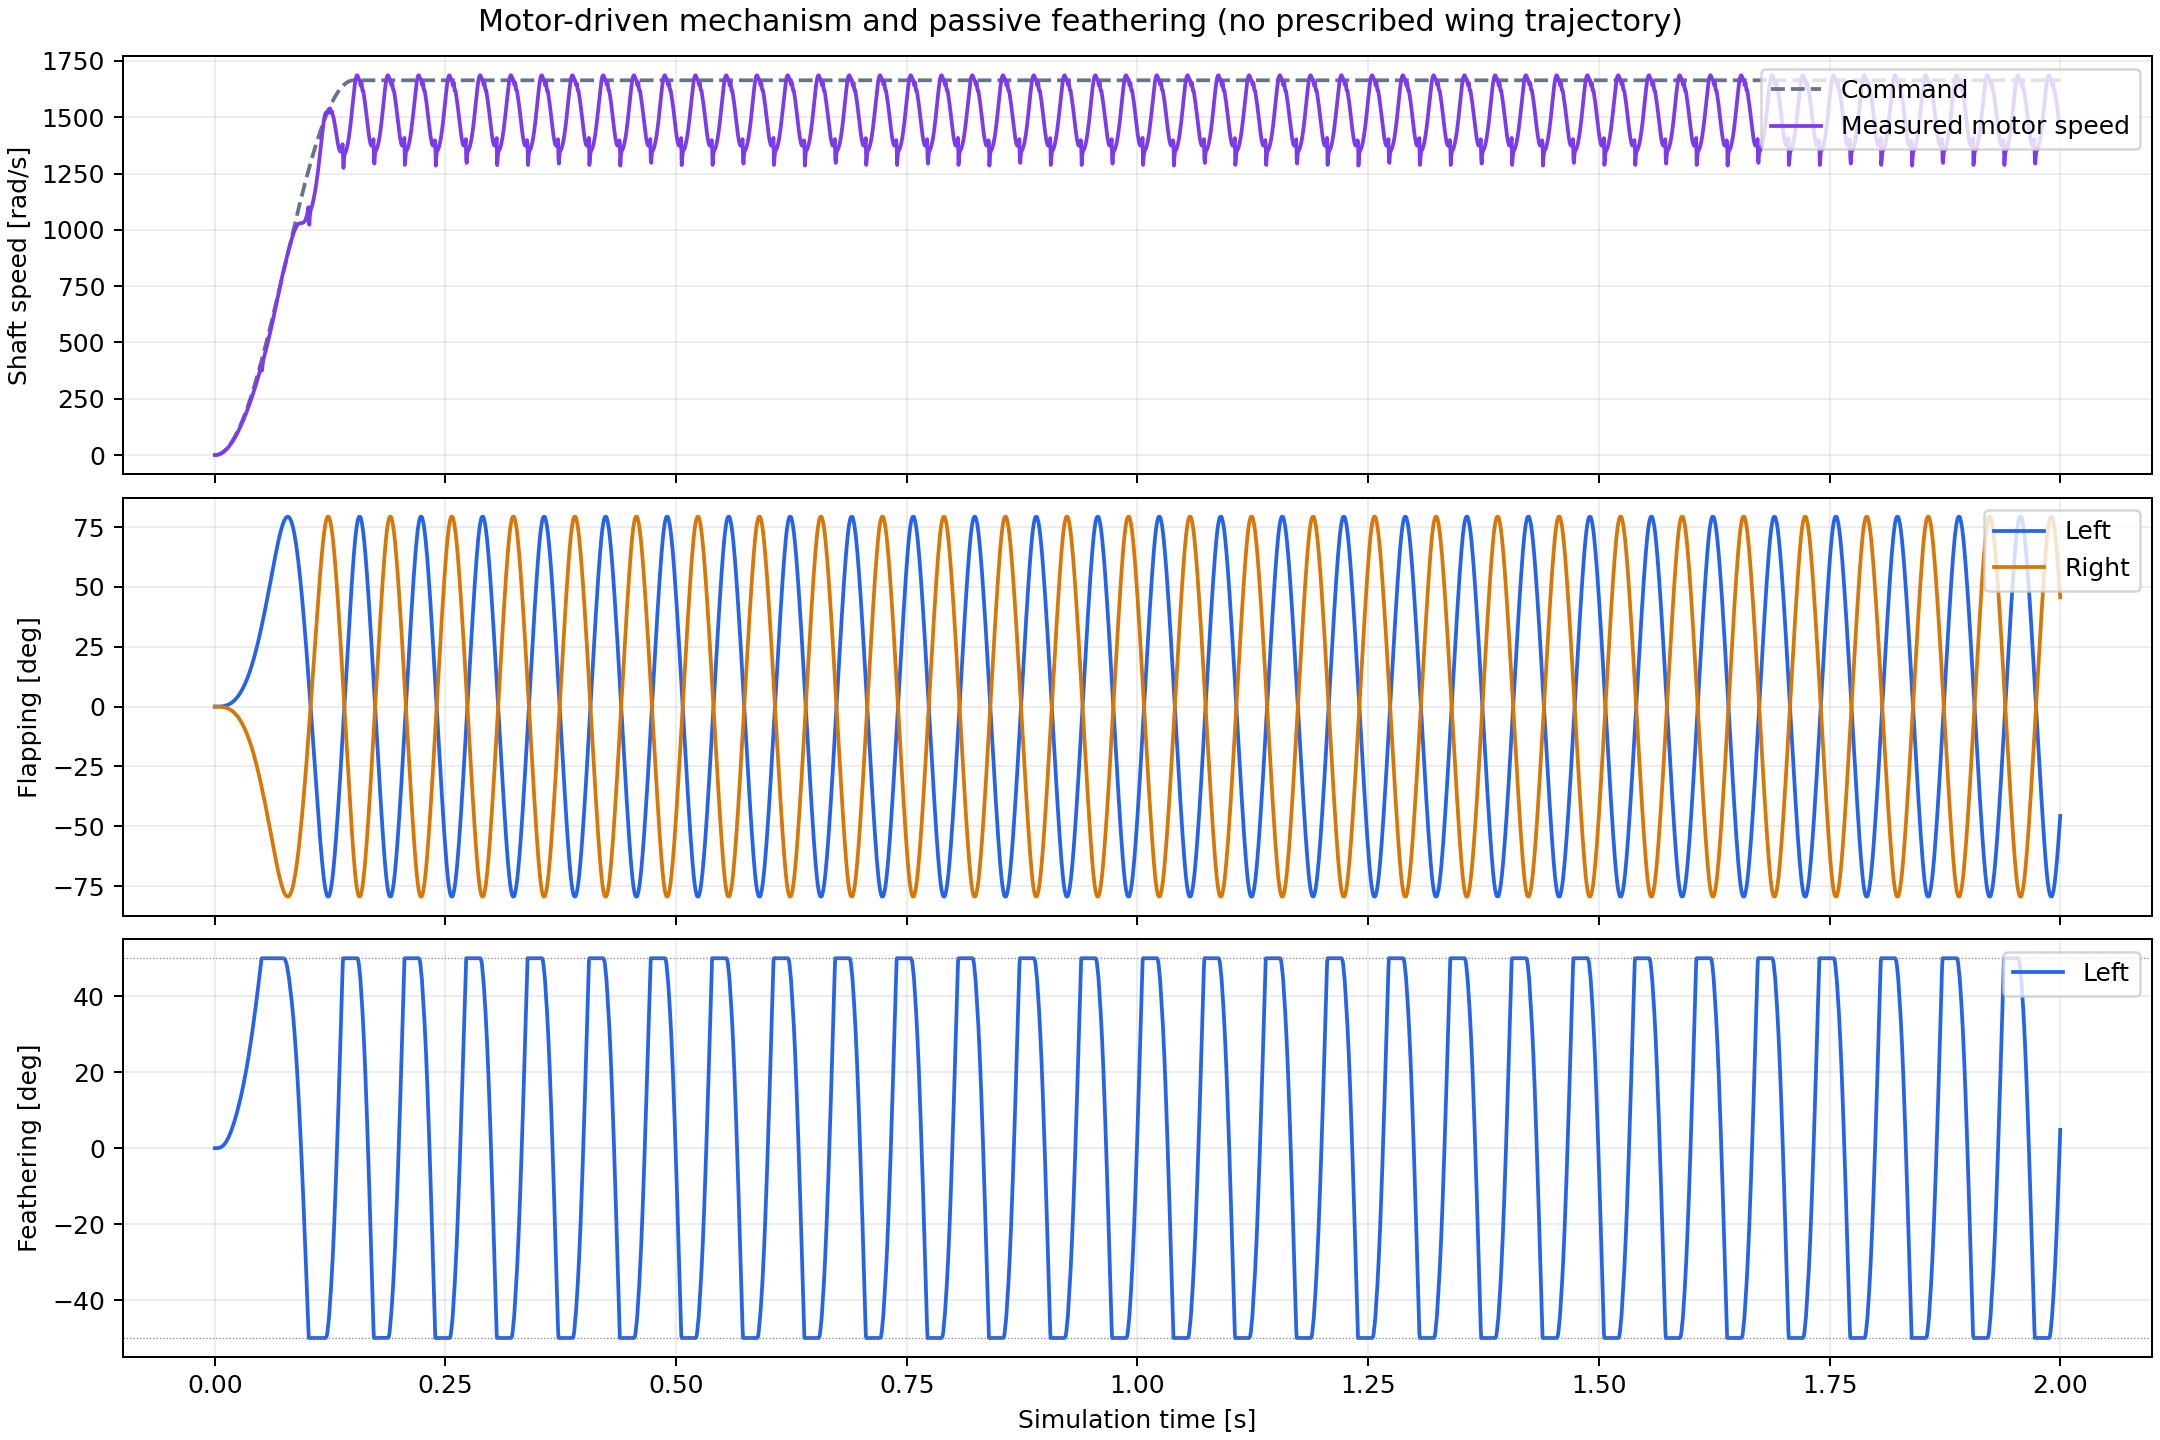

In [2]:
display(Image(filename=str(OUTPUT / '15hz' / 'wrench_6d.png')))
display(Image(filename=str(OUTPUT / '15hz' / 'joint_motion.png')))

复现：`python experiments/fixbase/single_wing_sweep.py`。
`results_single_wing_10_15hz/sweep.csv` 与 `sweep.json` 为汇总结果。
每组 `source_folder` 指向真实 CSV/NPZ、仿真参数及调速记录，包含单翼六维气动力和支座载荷。
`model/configuration.json` 记录拆除质量、保留机构及原模型哈希。